# EDA — ESCI (πλήρες dataset)

Διερευνητική ανάλυση του Shopping Queries Dataset (ESCI) σε **όλα** τα locales και
στις δύο εκδοχές (small/large). Όλοι οι υπολογισμοί γίνονται από τις συναρτήσεις του
`src/eda.py`, οπότε το notebook και το script δίνουν τα ίδια νούμερα
(`python -m src.eda` γράφει τα ίδια στο `results/eda/esci_full/`).

> Χρειάζεται ~6GB RAM (διαβάζονται όλα τα products για μήκη/missing πεδίων).

## 0. Τι δεδομένα έχουμε

Το ESCI είναι 3 αρχεία, στο `data/esci_data/esci-data/shopping_queries_dataset/`:

| Αρχείο | Μία γραμμή = | Βασικές στήλες |
|---|---|---|
| `..._examples.parquet` | ένα ζεύγος **(query, product)** με την ετικέτα του | `query_id`, `query`, `product_id`, `product_locale`, `esci_label`, `small_version`, `large_version`, `split` |
| `..._products.parquet` | ένα **product** (κατάλογος) | `product_id`, `product_locale`, `product_title`, `product_description`, `product_bullet_point`, `product_brand`, `product_color` |
| `..._sources.csv` | ένα **query** | `query_id`, `source` (από πού προήλθε το query) |

**Πώς δένουν:** examples ⟶ products με κλειδί `(product_id, product_locale)` (το ίδιο ASIN
μπορεί να υπάρχει σε πολλές χώρες) και examples ⟶ sources με `query_id`.

**Ετικέτες (`esci_label`)** — πόσο ταιριάζει το product στο query:
- **E**xact: είναι ακριβώς αυτό που ζητήθηκε
- **S**ubstitute: δεν είναι αυτό, αλλά θα μπορούσε να το αντικαταστήσει
- **C**omplement: δεν είναι αυτό, αλλά συνοδεύει (π.χ. θήκη για κινητό)
- **I**rrelevant: άσχετο

**Φίλτρα/στήλες που ορίζουν πειράματα:**
- `small_version` / `large_version`: δύο εκδοχές του dataset (η small είναι υποσύνολο, πιο «δύσκολη»).
- `product_locale`: `us`, `es`, `jp`.
- `split`: το επίσημο `train`/`test` της Amazon (ανά query).

**Η ροή στο repo:**
```
raw ESCI (3 αρχεία)
   └─ src/data.py : φίλτρο small_version==1 & us → merge → val 10% από train ανά query_id
        └─ data/processed/esci_small_us/{train,val,test}.parquet   ← σε αυτά εκπαιδεύονται/αξιολογούνται τα μοντέλα
   └─ src/eda.py  : στατιστικά σε όλο το dataset → results/eda/esci_full/
```
Το ESCI **δεν έχει κατηγορία προϊόντος** — γι' αυτό το φίλτρο «electronics» θα γίνει
αργότερα με join στο `meta_Electronics` (Amazon Reviews 2023).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Image, display

from src import eda
from src.data import load_config

pd.set_option("display.max_colwidth", 80)
cfg = load_config("configs/data.yaml")
RAW = ROOT / cfg["esci"]["raw_dir"]
OUT = ROOT / "results/eda/esci_full"
OUT.mkdir(parents=True, exist_ok=True)
eda.style()

## 1. Τα τρία αρχεία

### Examples (ζεύγη query–product)

In [2]:
ex = eda.load_examples(RAW, cfg)   # examples + στήλη source
print(ex.shape)
ex.head()

(2621288, 10)


,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split,source
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train,other
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train,other
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train,other
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train,other
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train,other


### Products (λίγες γραμμές — το αρχείο είναι ~1.1GB)

In [3]:
products_file = RAW / cfg["esci"]["products_file"]
print("products:", pq.ParquetFile(products_file).metadata.num_rows)
next(pq.ParquetFile(products_file).iter_batches(batch_size=3)).to_pandas()

products: 1814924


,product_id,product_title,product_description,product_bullet_point,product_brand,product_color,product_locale
0,B079VKKJN7,"11 Degrees de los Hombres Playera con Logo, Negro, L","Esta playera con el logo de la marca Carrier de 11 Degrees viene en negro, c...",11 Degrees Negro Playera con logo\nA estrenar y genuina. Somos un vendedor a...,11 Degrees,Negro,es
1,B079Y9VRKS,Camiseta Eleven Degrees Core TS White (M),NaN,NaN,11 Degrees,Blanco,es
2,B07DP4LM9H,"11 Degrees de los Hombres Core Pull Over Hoodie, Azul, S",La sudadera con capucha Core Pull Over de 11 Grados viene en color azul mari...,11 Degrees Azul Core Pull Over Hoodie\nA estrenar y genuina. Somos un vended...,11 Degrees,Azul,es


### Sources (πηγή κάθε query)

In [4]:
ex.drop_duplicates("query_id")["source"].value_counts()

source
other            113656
negations          6964
parse_pattern      6083
behavioral         3780
nlqec               169
Name: count, dtype: int64

### Παράδειγμα: ένα query με τα products του

Έτσι μοιάζει μία «εργασία» ranking: ένα query, τα υποψήφια products και η ετικέτα του καθενός.

In [5]:
qid = ex.loc[(ex["small_version"] == 1) & (ex["product_locale"] == "us") & (ex["split"] == "train"), "query_id"].iloc[0]
one = ex[(ex["query_id"] == qid) & (ex["small_version"] == 1)]
titles = pd.read_parquet(products_file, columns=["product_id", "product_title"],
                         filters=[("product_locale", "==", "us"), ("product_id", "in", list(one["product_id"]))])
print("query:", one["query"].iloc[0])
one.merge(titles, on="product_id")[["product_id", "esci_label", "product_title"]].sort_values("esci_label")

query: !awnmower tires without rims


,product_id,esci_label,product_title
6,B01M3SJ699,C,Dr.Roc Tire Spoon Lever Dirt Bike Lawn Mower Motorcycle Tire Changing Tools ...
1,B08L3B9B9P,E,"MaxAuto 2-Pack 13x5.00-6 2PLY Turf Mower Tractor Tire with Yellow Rim, (3"" C..."
4,B07C1WZG12,E,"(Set of 2) 15x6.00-6 Husqvarna/Poulan Tire Wheel Assy .75"" Bearing"
5,B077QMNXTS,E,"MaxAuto 2 Pcs 16x6.50-8 Lawn Mower Tire for Garden Tractors Ridings, 4PR, Tu..."
7,B06XX6BM2R,E,"MARASTAR 21446-2PK 15x6.00-6"" Front Tire Assembly Replacement-Craftsman Mowe..."
10,B0089RNSNM,E,Honda 42710-VE2-M02ZE (Replaces 42710-VE2-M01ZE) Lawn Mower Rear Wheel Set of 2
12,B005O5Y3QI,E,Carlisle Turf Saver Lawn & Garden Tire - 15X6-6 A
13,B0018TWDOI,E,Oregon 72-107 Universal Wheel 7X150 Diamond Plastic
0,B075SCHMPY,I,"RamPro 10"" All Purpose Utility Air Tires/Wheels with a 5/8"" Diameter Hole wi..."
2,B082K7V2GZ,I,NEIKO 20601A 14.5 inch Steel Tire Spoon Lever Iron Tool Kit | Professional T...


## 2. Μεγέθη ανά version / locale / split

In [6]:
ov = eda.overview(ex)
rows = []
for version in ["small_version", "large_version"]:
    for loc, splits in ov[version].items():
        for split, s in splits.items():
            rows.append({"version": version, "locale": loc, "split": split,
                         "rows": s["rows"], "queries": s["queries"], **s["label_dist"]})
print({k: ov[k] for k in ["rows", "queries", "products"]})
pd.DataFrame(rows)

{'rows': 2621288, 'queries': 130652, 'products': 1814883}


,version,locale,split,rows,queries,E,S,C,I
0,small_version,es,test,65883,2417,0.4109,0.3409,0.0744,0.1738
1,small_version,es,train,152891,5632,0.4129,0.3323,0.0817,0.1731
2,small_version,jp,test,88789,3123,0.4685,0.3329,0.0454,0.1532
3,small_version,jp,train,209094,7284,0.4599,0.3324,0.0429,0.1648
4,small_version,us,test,181701,8956,0.4387,0.3498,0.0446,0.1669
5,small_version,us,train,419653,20888,0.4333,0.3518,0.0455,0.1695
6,large_version,es,test,93347,3844,0.5319,0.2730,0.0586,0.1364
7,large_version,es,train,263063,11336,0.5794,0.2417,0.0571,0.1218
8,large_version,jp,test,118907,4667,0.5581,0.2760,0.0375,0.1284
9,large_version,jp,train,327146,13460,0.5874,0.2541,0.0325,0.1260


## 3. Κατανομή ετικετών

Η small version έχει πολύ λιγότερα E από τη large — γι' αυτό αποτελέσματα στις δύο
δεν συγκρίνονται μεταξύ τους. Το C είναι παντού η σπάνια κλάση (→ macro-F1).

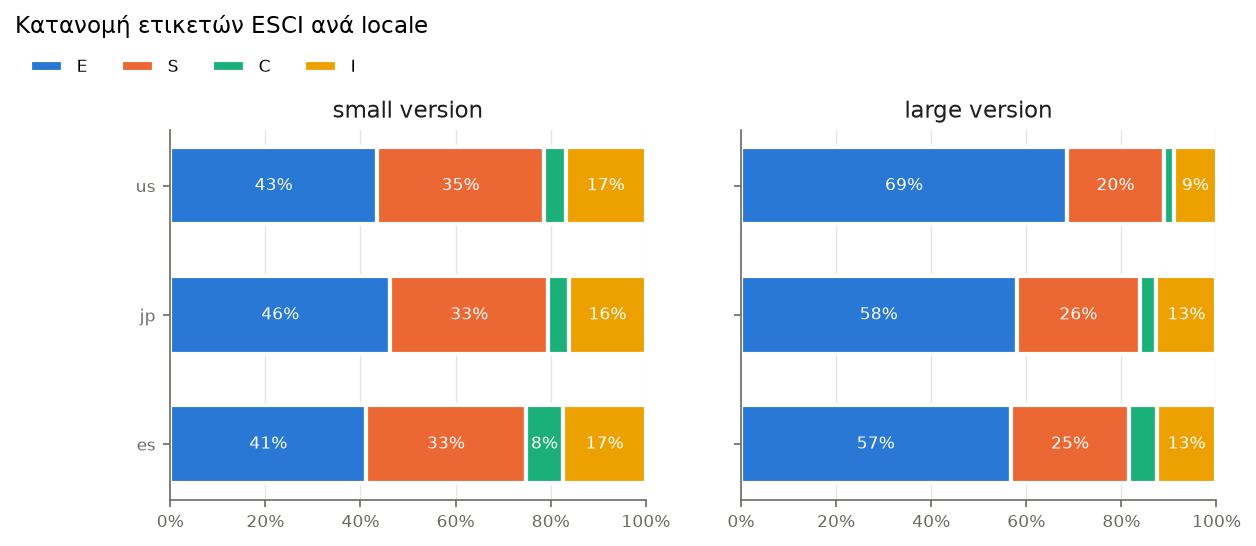

In [7]:
eda.fig_labels_by_locale(ov, OUT)
display(Image(OUT / "labels_by_locale.png"))

## 4. Ανά query: υποψήφια products και μήκος query (small version)

In [8]:
q, per_query_stats = eda.per_query(ex)
pd.DataFrame({loc: {k: v for k, v in s.items() if not isinstance(v, dict)}
              for loc, s in per_query_stats.items()})

,es,jp,us
queries,8049.000,10407.000,29844.0000
share_queries_with_E,1.000,1.000,1.0000
share_queries_without_E,0.000,0.000,0.0000
share_queries_all_E,0.000,0.000,0.0000
share_queries_with_C,0.444,0.344,0.2581


In [9]:
pd.concat({loc: pd.Series(s["candidates_per_query"]) for loc, s in per_query_stats.items()}, axis=1)

,es,jp,us
count,8049.00,10407.00,29844.00
mean,27.18,28.62,20.15
std,11.63,12.49,9.48
min,8.00,8.00,8.00
25%,16.00,16.00,16.00
50%,22.00,33.00,16.00
75%,40.00,40.00,16.00
95%,40.00,45.00,40.00
max,77.00,96.00,188.00


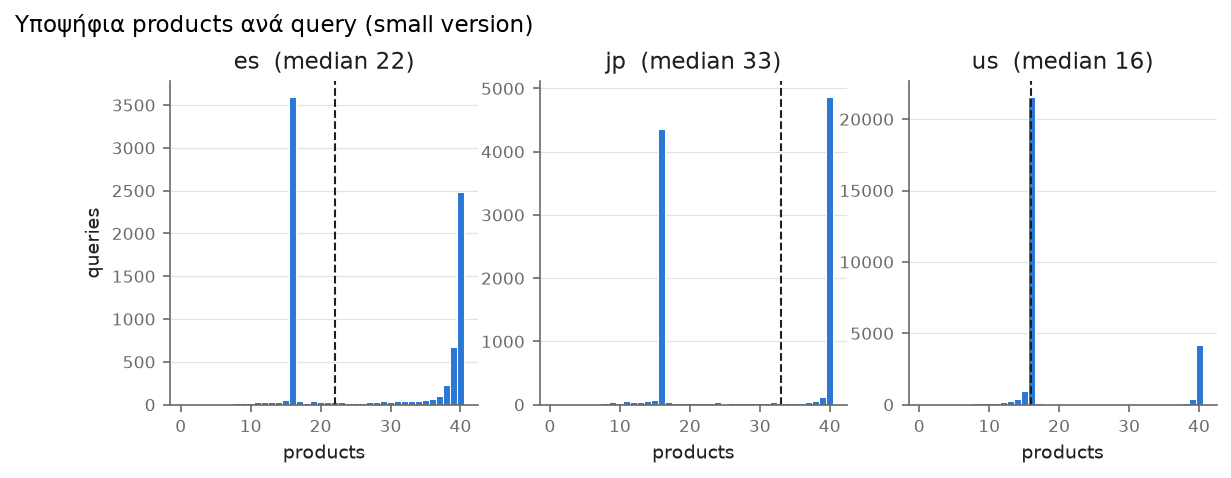

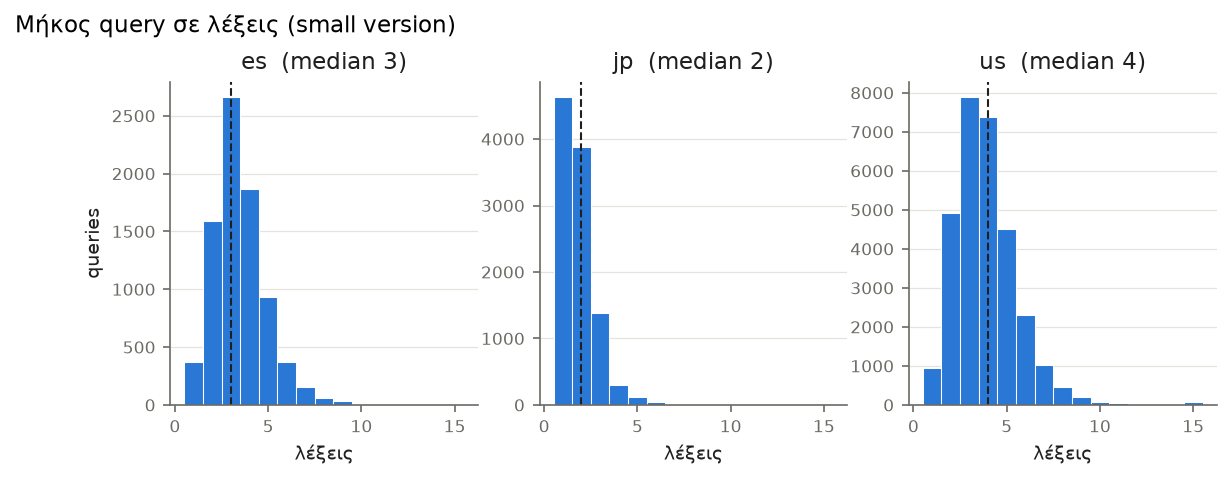

In [10]:
eda.fig_hist(q, "n", "Υποψήφια products ανά query (small version)", "products",
             OUT, "candidates_per_query.png", clip=40)
eda.fig_hist(q, "q_words", "Μήκος query σε λέξεις (small version)", "λέξεις",
             OUT, "query_length.png", clip=15)
display(Image(OUT / "candidates_per_query.png"), Image(OUT / "query_length.png"))

## 5. Ετικέτες ανά μήκος και πηγή query (small, us)

Μακριά queries και οι πηγές `nlqec` / `negations` έχουν πολύ περισσότερα I —
υποψήφιες «δύσκολες» ομάδες για το error analysis.

esci_label,E,S,C,I,rows
query_id,,,,,
1-2,0.4626,0.2846,0.0643,0.1885,111659
3-4,0.4411,0.3606,0.0461,0.1522,302045
5-6,0.4234,0.3768,0.0341,0.1657,143090
7-10,0.3729,0.3855,0.0263,0.2153,40914
11+,0.2216,0.2211,0.0387,0.5187,3646


esci_label,E,S,C,I,queries
source,,,,,
behavioral,0.4478,0.3183,0.0448,0.1890,762
negations,0.3739,0.2894,0.0234,0.3133,2318
nlqec,0.2370,0.2048,0.0459,0.5123,99
other,0.4400,0.3622,0.0516,0.1461,24107
parse_pattern,0.4621,0.3641,0.0335,0.1403,2558


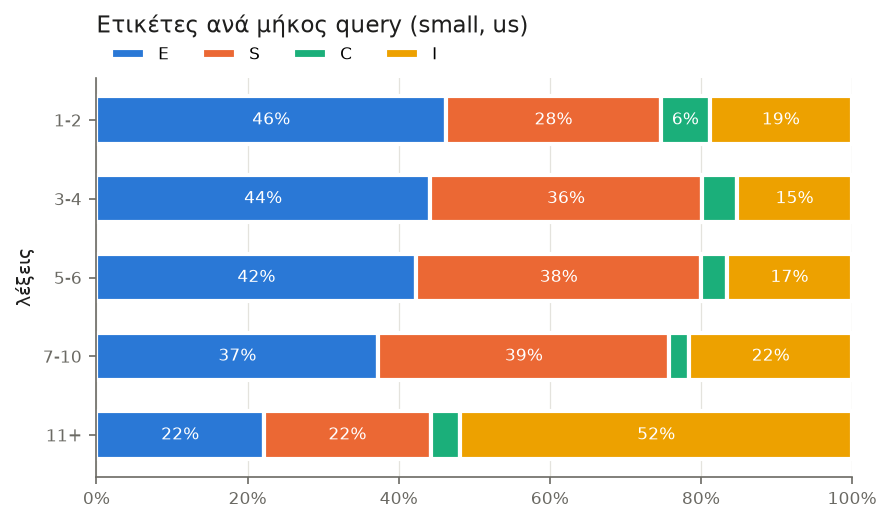

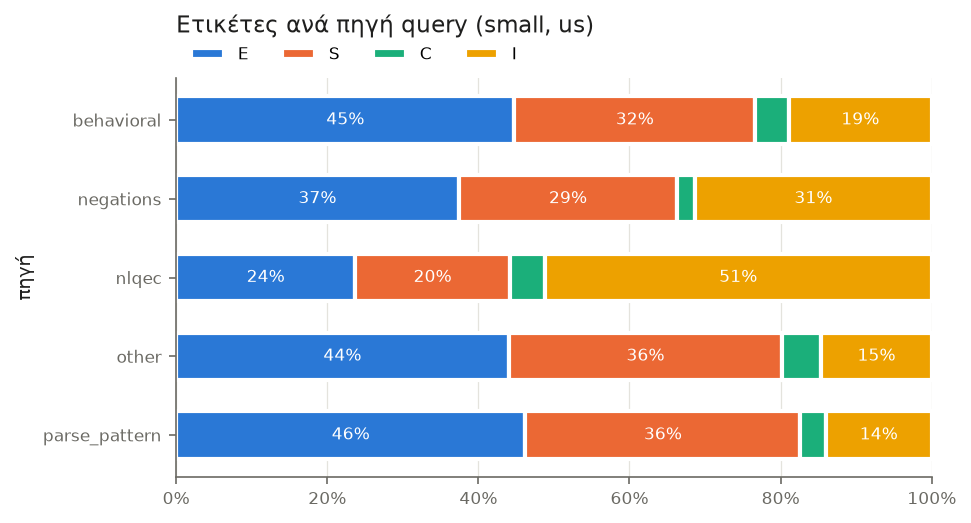

In [11]:
by_len, by_src = eda.label_by_bucket(ex, q)
display(by_len, by_src)
eda.fig_stacked_table(by_len, "Ετικέτες ανά μήκος query (small, us)", "λέξεις",
                      OUT, "labels_by_query_length_us.png")
eda.fig_stacked_table(by_src, "Ετικέτες ανά πηγή query (small, us)", "πηγή",
                      OUT, "labels_by_query_source_us.png")
display(Image(OUT / "labels_by_query_length_us.png"), Image(OUT / "labels_by_query_source_us.png"))

## 6. Πεδία products: τι λείπει και πόσο μεγάλα είναι

Μετρημένο στα μοναδικά products της small version. Κενό string μετράει ως missing.

Ποσοστό missing:


,product_title,product_description,product_bullet_point,product_brand,product_color
product_locale,,,,,
es,0.0,0.4555,0.1346,0.0504,0.3971
jp,0.0,0.5570,0.2496,0.1717,0.5488
us,0.0,0.4778,0.1320,0.0564,0.3218


Διάμεσος μήκους (χαρακτήρες):


,product_title,product_description,product_bullet_point,product_brand,product_color
product_locale,,,,,
es,118.0,950.0,615.0,7.0,6.0
jp,54.0,250.0,182.0,8.0,4.0
us,97.0,761.0,588.0,8.0,6.0


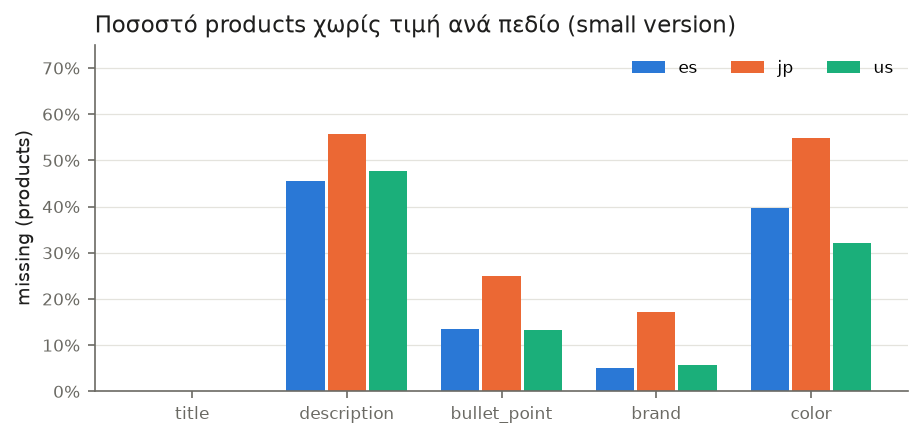

In [12]:
ps, us_brands = eda.product_stats(products_file, sorted(ex["product_locale"].unique()))
miss, lengths = eda.missingness(ex, ps)
del ps
print("Ποσοστό missing:"); display(miss)
print("Διάμεσος μήκους (χαρακτήρες):"); display(lengths)
eda.fig_missing(miss, OUT)
display(Image(OUT / "missing_fields.png"))

## 7. Επικάλυψη train/test (small, us)

In [13]:
eda.overlap(ex)

{'query_id_overlap_train_test': 0,
 'query_text_overlap_train_test': 0,
 'test_products_seen_in_train': 0.2108,
 'products_in_multiple_queries': 0.1377}

## 8. Συχνότερα brands στον us κατάλογο

Δείχνει τι είδους προϊόντα έχει το ESCI συνολικά — όχι μόνο electronics.

In [14]:
us_brands.value_counts().head(20)

product_brand
Nike                 6160
adidas               4427
Amazon Essentials    4405
Under Armour         3103
Disney               2994
Hanes                2783
Amazon Basics        2652
Skechers             2066
Generic              1958
Columbia             1952
Unknown              1844
Rubie's              1777
Champion             1763
LEGO                 1730
Calvin Klein         1693
Levi's               1621
Carhartt             1598
Apple                1480
New Balance          1433
HP                   1377
Name: count, dtype: int64

## 9. Συμπεράσματα

Τα νούμερα παραπάνω (και στο `results/eda/esci_full/summary.json`) δείχνουν:

1. **small ≠ large**: η large version είναι πολύ πιο E-heavy· δουλεύουμε στη small (us) και δεν συγκρίνουμε αποτελέσματα μεταξύ τους.
2. **C σπάνιο**: η κλάση C είναι η μικρότερη και λείπει από τα περισσότερα queries → macro-F1 και ανάλυση ανά κλάση.
3. **Ranking 16–40 υποψηφίων** ανά query (us: συνήθως 16 ή 40) → το nDCG@10 έχει νόημα.
4. **Μακριά / `nlqec` / `negations` queries** έχουν πολλά I → ξεχωριστή αναφορά στο error analysis.
5. **Κείμενο product**: το title υπάρχει πάντα, το description λείπει σε σχεδόν μισά products → βάση το title + bullet points.
6. **Χωρίς leakage queries** train/test· ένα μέρος των test products εμφανίζεται και στο train.
7. **Ο κατάλογος είναι γενικός** (ρούχα, παιχνίδια κ.λπ.) → χρειάζεται φίλτρο electronics μέσω `meta_Electronics`.